<a href="https://colab.research.google.com/github/maytediaz0226-debug/M-todos-num-ricos-/blob/main/Cuadratura_adaptable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

METODOS NUMERICOS II
<h1 style="font=family:Georgia;font-size:40px;">
CUADRATURA ADAPTABLE
</h1>
Nombre: Mayte Diaz Bojorges




<h1 style="font-family=Georgia;">
Introducción
</h1>

Se implementara el metodo de cuadratura adaptable, este metodo utiliza la regla de Simpson para aproximar una integral definida y estima si es necesario subdividir el intervalo de integración para mejorar la precision del resultado.

A diferencia de otros metodos la cuadratura adaptable ajusta el procedimiento segun la diferencia entre las aproximaciones obtenidas. Cuando no se satisface el criterio de aceptacion, el intervalo se divide en dos partes y se repite el calculo hasta cumplir la tolerancia establecida o alcanzar el nivel máximo permitido.

La regla de Simpson permite aproximar una integral de la forma:

$$I=\int_a^b f(x),dx$$

mediante la expresion:

$$S=\frac{h}{3}\left[f(a)+4f(a+h)+f(b)\right],
\qquad h=\frac{b-a}{2}$$

En la cuadratura adaptable, esta aproximacion se compara con la suma de las aproximaciones calculadas en las dos mitades del intervalo:

$$S_{\mathrm{nuevo}}=S_1+S_2.$$

La decision de aceptar el resultado se basa en el criterio de error establecido en el algoritmo. Si la diferencia entre ambas aproximaciones no satisface la tolerancia, se subdivide el intervalo y se repite el procedimiento.


**Planteamiento del problema**

Se utilizara la funcion:

$$f(x)=\frac{100}{x^2}\sin\left(\frac{10}{x}\right)$$

El problema consiste en calcular

$$I=\int_1^3\frac{100}{x^2}
\sin\left(\frac{10}{x}\right)\,dx$$

Los datos del problema son:

limite inferior: $a=1$.

limite superior: $b=3$.

tolerancia: $TOL=10^{-4}$.

nivel maximo: $N=30$.

Obtener una aproximacion numerica de la integral mediante el Algoritmo 4.3 de Burden.

Para aproximar la integral en el intervalo $[a,b]$, se define

$$h=\frac{b-a}{2}$$

La aproximacion inicial mediante la regla de Simpson es

$$S=\frac{h}{3}\left[f(a)+4f(a+h)+f(b)\right]$$

Se evaluan dos aproximaciones de Simpson en las mitades del intervalo

$$S_1=\frac{h}{6}
\left[f(a)+4f\left(a+\frac{h}{2}\right)+f(a+h)\right]$$

$$S_2=\frac{h}{6}
\left[f(a+h)+4f\left(a+\frac{3h}{2}\right)+f(b)\right]$$

La aproximacion refinada es

$$S_{\text{nuevo}}=S_1+S_2$$

El algoritmo acepta la aproximacion cuando:

$${|S_1+S_2-S|<TOL_i}$$

La tolerancia inicial interna se establece como:

$$TOL_i=10TOL$$

Cuando es necesario subdividir el intervalo, la tolerancia de cada subintervalo se reduce a la mitad:

$$TOL_{i+1}=\frac{TOL_i}{2}$$

Si se satisface el criterio, se acumula $S_1+S_2$. En caso contrario, se repite el procedimiento en ambos subintervalos, hasta satisfacer el criterio o alcanzar el nivel maximo permitido.

In [14]:
import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.figsize"] = (10, 5)


In [15]:
def f(x):

    return (100 / x**2) * math.sin(10 / x)

a = 1.0
b = 3.0
TOL = 1e-4
N = 30

print("Funcion: f(x) = (100/x²) sen(10/x)")
print(f"Limite inferior a = {a}")
print(f"Limite superior b = {b}")
print(f"Tolerancia = {TOL}")
print(f"Nivel maximo = {N}")

Funcion: f(x) = (100/x²) sen(10/x)
Limite inferior a = 1.0
Limite superior b = 3.0
Tolerancia = 0.0001
Nivel maximo = 30


El procedimiento se implementara mediante una función recursiva.

Primero se calcula la aproximacion inicial de Simpson. Posteriormente, se evaluan los puntos interiores de las dos mitades del intervalo y se calcula la diferencia entre la aproximacion refinada y la aproximacion inicial.

Si la diferencia es menor que la tolerancia interna, se acepta el resultado. Si no se cumple, se subdivide el intervalo y se repite el proceso.

La funcion tambien contara las evaluaciones realizadas y verificara que no se exceda el nivel maximo permitido.

In [16]:
evaluaciones = 0


def evaluar(x):
    global evaluaciones
    evaluaciones += 1
    return f(x)


def cuadratura_adaptable(a, b, TOL, N=30):
    global evaluaciones
    evaluaciones = 0

    if TOL <= 0:
        raise ValueError("La tolerancia debe ser positiva.")

    if a == b:
        return 0.0

    signo = 1.0

    if a > b:
        a, b = b, a
        signo = -1.0

    h = (b - a) / 2

    FA = evaluar(a)
    FC = evaluar(a + h)
    FB = evaluar(b)

    S = h * (FA + 4 * FC + FB) / 3

    tolerancia_inicial = 10 * TOL

    def procesar(a_i, h_i, FA_i, FC_i, FB_i,
                 S_i, TOL_i, nivel):

        FD = evaluar(a_i + h_i / 2)
        FE = evaluar(a_i + 3 * h_i / 2)
        S1 = h_i * (FA_i + 4 * FD + FC_i) / 6
        S2 = h_i * (FC_i + 4 * FE + FB_i) / 6
        diferencia = abs(S1 + S2 - S_i)

        if diferencia < TOL_i:
            return S1 + S2

        if nivel >= N:
            raise RuntimeError(
                "Se alcanzó el nivel máximo sin satisfacer "
                "el criterio de tolerancia."
            )

        izquierda = procesar(
            a_i,
            h_i / 2,
            FA_i,
            FD,
            FC_i,
            S1,
            TOL_i / 2,
            nivel + 1
        )

        derecha = procesar(
            a_i + h_i,
            h_i / 2,
            FC_i,
            FE,
            FB_i,
            S2,
            TOL_i / 2,
            nivel + 1
        )
        return izquierda + derecha

    aproximacion = procesar(
        a, h, FA, FC, FB,
        S, tolerancia_inicial, 1
    )

    return signo * aproximacion


print("Algoritmo 4.3 implementado correctamente.")

Algoritmo 4.3 implementado correctamente.


In [17]:
resultado = cuadratura_adaptable(a, b, TOL, N)
print("RESULTADOS")

print(f"Intervalo de integracion: [{a}, {b}]")
print(f"Tolerancia: {TOL:.1e}")
print(f"Nivel maximo: {N}")
print(f"Evaluaciones de f(x): {evaluaciones}")
print(f"Integral aproximada: {resultado:.12f}")

RESULTADOS
Intervalo de integracion: [1.0, 3.0]
Tolerancia: 1.0e-04
Nivel maximo: 30
Evaluaciones de f(x): 93
Integral aproximada: -1.426014810049


Representacion grafica de la funcion $f(x)=\frac{100}{x^2}\sin\left(\frac{10}{x}\right)$

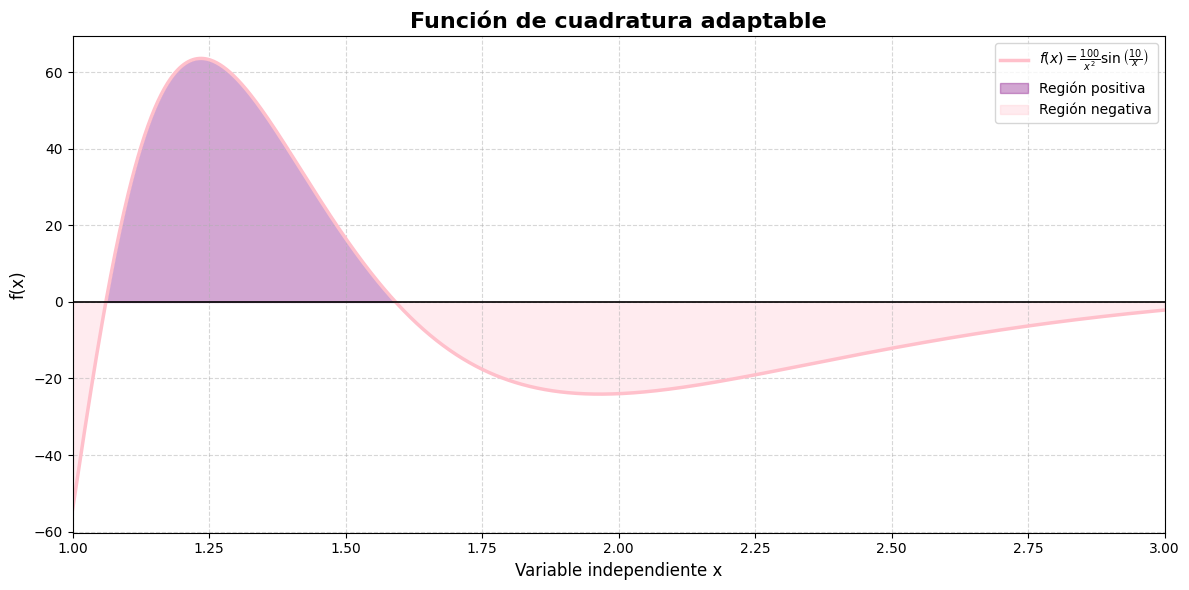

In [18]:
x = np.linspace(a, b, 1000)
y = (100 / x**2) * np.sin(10 / x)

plt.figure(figsize=(12, 6))
plt.plot( x, y, color="pink",
    linewidth=2.5,
    label=r"$f(x)=\frac{100}{x^2}\sin\left(\frac{10}{x}\right)$"
)

plt.axhline(
    y=0,
    color="black",
    linewidth=1.2
)

plt.fill_between(x, y, 0, where=(y >= 0), color="purple", alpha=0.35, interpolate=True,label="Región positiva")

plt.fill_between(x, y, 0,where=(y < 0),color="pink",alpha=0.30,interpolate=True,label="Región negativa")

plt.title("Función de cuadratura adaptable",fontsize=16,fontweight="bold")

plt.xlabel("Variable independiente x", fontsize=12)
plt.ylabel("f(x)", fontsize=12)

plt.xlim(a, b)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [19]:
valor_exacto = 10 * (math.cos(10 / b) - math.cos(10 / a))

error_absoluto = abs(resultado - valor_exacto)

print("COMPROBACIÓN DE LA APROXIMACION")

print(f"Aproximacion numerica: {resultado:.12f}")
print(f"Valor analitico:       {valor_exacto:.12f}")
print(f"Error absoluto:        {error_absoluto:.10e}")
print(f"Tolerancia:            {TOL:.1e}")

if error_absoluto < TOL:
    print("\nLa aproximacion cumple la tolerancia solicitada.")
else:
    print("\nEl error supera la tolerancia solicitada.")

COMPROBACIÓN DE LA APROXIMACION
Aproximacion numerica: -1.426014810049
Valor analitico:       -1.426024756346
Error absoluto:        9.9462968211e-06
Tolerancia:            1.0e-04

La aproximacion cumple la tolerancia solicitada.


**CONCLUSION**

Se implemento el Algoritmo 4.3 de cuadratura adaptable de Burden mediante Python, utilizando la regla de Simpson para aproximar una integral definida.

El procedimiento subdivide el intervalo cuando la diferencia entre la aproximacion inicial y la refinada no satisface la tolerancia interna. Esto permite distribuir las subdivisiones segun las necesidades de precisión del calculo.

En la grafica podemos identificar las regiones positivas y negativas de la funcion, mientras que la comprobacion analitica permitio evaluar la precision de la aproximacion numerica .

La integral estudiada es:

$$I=\int_1^3\frac{100}{x^2}
\sin\left(\frac{10}{x}\right)\,dx$$

El valor aproximado obtenido mediante el algoritmo es

$${I\approx -1.426014810}$$

El resultado demuestra la utilidad de la cuadratura adaptable para calcular integrales numericamente con una tolerancia establecida.